# Entrenamiento de CNN ResNet-18 con Transfer Learning
## Objetivos

- Construir un modelo baseline de clasificación mediante transfer learning con ResNet18 preentrenada.
- Congelar el extractor de características y entrenar únicamente la capa clasificadora final.
- Aplicar transformaciones y aumentación de datos al conjunto de entrenamiento.
- Entrenar y validar el modelo registrando loss y accuracy por época.
- Evaluar el modelo de la última época sobre el conjunto de prueba.
- Analizar los resultados mediante accuracy, precision, recall, F1-score, reporte de clasificación y matriz de confusión normalizada.
- Guardar los pesos finales del modelo entrenado.

In [1]:
# Importaciones
import matplotlib.pyplot as plt

from vasijas.paths import ProjectPaths
from vasijas.config import load_config
from vasijas.entrenamiento_cnn import (
    ConfiguracionSplitDataset,
    ConfiguracionTransformacionesImagen,
    calcular_resultado_clasificacion,
    crear_criterio_entropia_cruzada,
    crear_dataloaders_imagen,
    crear_modelo_transfer_learning,
    crear_optimizador_adam,
    describir_dispositivo,
    describir_metricas_epoch,
    entrenar_modelo,
    graficar_historial_entrenamiento,
    graficar_lote_imagenes,
    graficar_matriz_confusion,
    guardar_pesos_modelo,
    seleccionar_dispositivo_procesamiento,
    validar_modelo,
)

In [2]:
# Configuracion general
CONFIG = load_config()
PATHS = ProjectPaths.from_root(CONFIG.project_root)

## Dispositivo para procesamiento

In [3]:
DEVICE = seleccionar_dispositivo_procesamiento()
print(describir_dispositivo(DEVICE))

Dispositivo utilizado para procesamiento: CPU


In [5]:
# Parámetros

# Modelo
MODEL_NAME = "resnet18"
RUN_NAME = "default"

# Entrenamiento
BATCH_SIZE = 16
EPOCHS = 30
LR = 1e-3

# Preprocesamiento
IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Aumentación de datos
FLIP_PROBABILITY = 0.5
SCALING_FACTOR_INTERVAL = (0.7, 1.0)
ROTATION_DEGREES = 15
PIXEL_FILL = (255, 255, 255)

# Reproducibilidad
SEED = 42

# Ruta de datos de entrada
DATA_DIR = PATHS.DATA_CUADRADOS

In [9]:
# Transformaciones y dataloaders
config_transformaciones = ConfiguracionTransformacionesImagen(
    tamano_imagen=IMG_SIZE,
    probabilidad_flip=FLIP_PROBABILITY,
    intervalo_escalado=SCALING_FACTOR_INTERVAL,
    grados_rotacion=ROTATION_DEGREES,
    relleno_pixeles=PIXEL_FILL,
    media_normalizacion=IMAGENET_MEAN,
    desvio_normalizacion=IMAGENET_STD,
)
config_split = ConfiguracionSplitDataset(semilla=SEED)

dataloaders = crear_dataloaders_imagen(
    data_dir=DATA_DIR,
    batch_size=BATCH_SIZE,
    configuracion_transformaciones=config_transformaciones,
    configuracion_split=config_split,
)

train_loader = dataloaders.train
val_loader = dataloaders.val
test_loader = dataloaders.test
class_names = dataloaders.class_names
NUM_CLASSES = dataloaders.num_classes

print("Clases:", class_names)
print(
    f"Split -> train: {len(train_loader.dataset)}, "
    f"val: {len(val_loader.dataset)}, "
    f"test: {len(test_loader.dataset)}"
)

Clases: ['clase01', 'clase02', 'clase03', 'clase04', 'clase05', 'clase06', 'clase07', 'clase08', 'clase09', 'clase10', 'clase11', 'sin_clase']
Split -> train: 869, val: 186, test: 187


In [5]:
# Visualización rápida (sanity check)
graficar_lote_imagenes(
    loader=train_loader,
    nombres_clases=class_names,
)
plt.show()

model = crear_modelo_transfer_learning(
    nombre_modelo=MODEL_NAME,
    num_classes=NUM_CLASSES,
    dispositivo=DEVICE,
)

In [6]:
# Criterio y optimizador
criterion = crear_criterio_entropia_cruzada()
optimizer = crear_optimizador_adam(model, learning_rate=LR)

In [7]:
# Entrenamiento y validación
historial = entrenar_modelo(
    modelo=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterio=criterion,
    optimizador=optimizer,
    dispositivo=DEVICE,
    epochs=EPOCHS,
    al_finalizar_epoch=lambda metrica: print(
        describir_metricas_epoch(metrica, total_epochs=EPOCHS)
    ),
)

Epoch 1/30
Train Loss: 1.9003 | Train Acc: 0.3901
Val Loss: 1.7937 | Val Acc: 0.3710
Tiempo de epoch: 0:00:22.188745
Epoch 2/30
Train Loss: 1.5097 | Train Acc: 0.5270
Val Loss: 1.5325 | Val Acc: 0.4785
Tiempo de epoch: 0:00:21.087976
Epoch 3/30
Train Loss: 1.3660 | Train Acc: 0.5616
Val Loss: 1.4457 | Val Acc: 0.5645
Tiempo de epoch: 0:00:20.881429
Epoch 4/30
Train Loss: 1.2934 | Train Acc: 0.6041
Val Loss: 1.4271 | Val Acc: 0.5430
Tiempo de epoch: 0:00:21.020969
Epoch 5/30
Train Loss: 1.2104 | Train Acc: 0.6133
Val Loss: 1.4430 | Val Acc: 0.4946
Tiempo de epoch: 0:00:20.943579
Epoch 6/30
Train Loss: 1.1745 | Train Acc: 0.6410
Val Loss: 1.2604 | Val Acc: 0.6022
Tiempo de epoch: 0:00:21.015747
Epoch 7/30
Train Loss: 1.1224 | Train Acc: 0.6352
Val Loss: 1.2633 | Val Acc: 0.6022
Tiempo de epoch: 0:00:20.836641
Epoch 8/30
Train Loss: 1.0795 | Train Acc: 0.6605
Val Loss: 1.1988 | Val Acc: 0.6237
Tiempo de epoch: 0:00:20.812534
Epoch 9/30
Train Loss: 1.0586 | Train Acc: 0.6640
Val Loss: 1.21

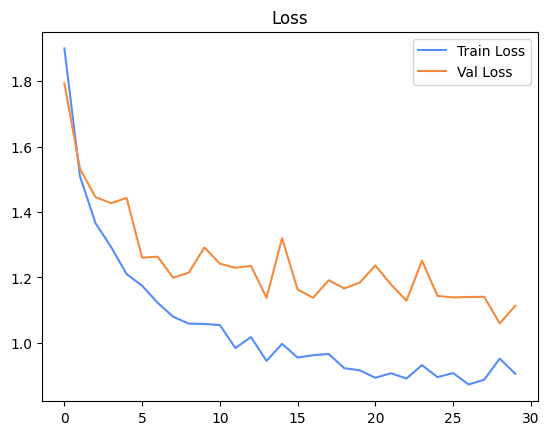

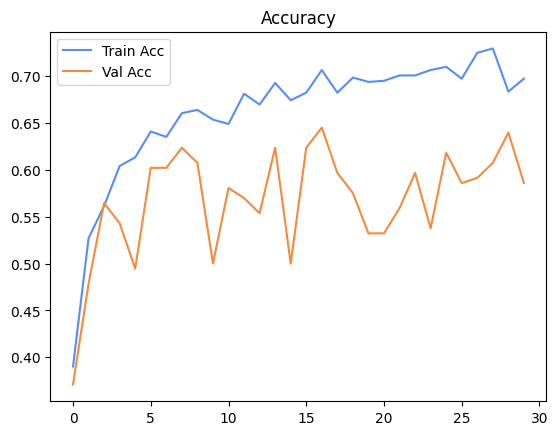

In [8]:
# Curvas de entrenamiento
graficar_historial_entrenamiento(historial)
plt.show()

Test Acc: 0.6043
              precision    recall  f1-score   support

     clase01       0.00      0.00      0.00         4
     clase02       0.50      0.29      0.36         7
     clase03       0.83      0.45      0.59        11
     clase04       0.00      0.00      0.00         1
     clase05       0.29      1.00      0.45         9
     clase06       0.50      0.14      0.22         7
     clase07       0.50      0.14      0.22         7
     clase08       0.83      0.60      0.69        42
     clase09       0.00      0.00      0.00         3
     clase10       0.86      0.91      0.88        54
     clase11       0.83      0.83      0.83        18
   sin_clase       0.17      0.25      0.20        24

    accuracy                           0.60       187
   macro avg       0.44      0.38      0.37       187
weighted avg       0.66      0.60      0.60       187



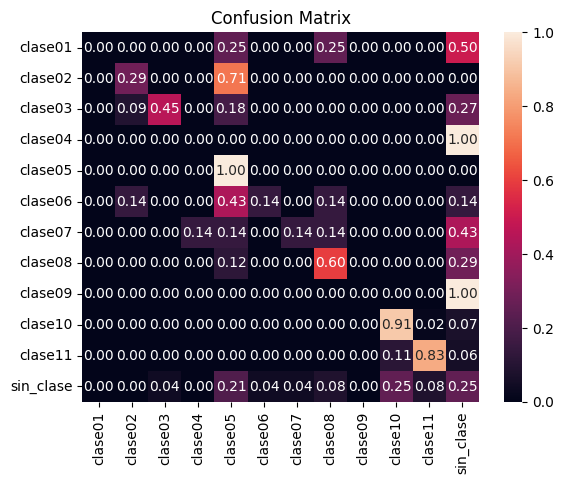

In [9]:
# Evaluación final
resultado_test = validar_modelo(
    modelo=model,
    loader=test_loader,
    criterio=criterion,
    dispositivo=DEVICE,
)
resultado_clasificacion = calcular_resultado_clasificacion(
    resultado=resultado_test,
    nombres_clases=class_names,
)

print(f"Test Acc: {resultado_test.accuracy:.4f}")
print(resultado_clasificacion.reporte)

graficar_matriz_confusion(
    matriz=resultado_clasificacion.matriz_confusion,
    nombres_clases=class_names,
)
plt.show()

In [10]:
# Guardado del modelo
ruta_modelo = guardar_pesos_modelo(
    modelo=model,
    ruta_destino=PATHS.OUTPUT_MODELS / f"model_{MODEL_NAME}_{RUN_NAME}.pth",
)
print(f"Modelo guardado en: {ruta_modelo}")